# Herramientas de Probabilidad en Python · Caso BancoSur

**Sesión 3 · Probabilidad Aplicada · Data Science for Business · Futura**

Marta Echevarría, CRO de BancoSur, necesita responder cinco preguntas
de su dashboard con probabilidad. Cada pregunta esconde una distribución
diferente. Esta notebook es el manual operativo para responderlas en Python.

Para cada distribución vas a aprender el **kit completo**:

| Operación | Pregunta de negocio que responde |
|---|---|
| `rvs(size=...)` | Simular ensayos reales del proceso |
| `pmf(k)` o `pdf(x)` | ¿Qué tan probable es el valor exacto x? |
| `cdf(x)` | ¿Qué tan probable es que el valor sea menor o igual que x? |
| `ppf(q)` | ¿Qué valor deja el q% de la probabilidad por debajo? |
| `mean()`, `var()`, `std()` | Esperanza, varianza, desviación estándar teóricas |


## Mapa de distribuciones del caso BancoSur

| Sector | Pregunta operativa | Distribución |
|---|---|---|
| Banca · A/B test scoring | ¿Subió la tasa de aprobación? | **Bernoulli y Binomial** |
| Banca · antifraude | ¿Cuántos analistas dimensionamos? | **Poisson** |
| Banca · préstamos personales | ¿Cuál es el ticket típico? | **Log-normal** |
| Banca · cartera de créditos | ¿Cuándo defaultean? | **Exponencial** |
| Gaming · payout máquinas | ¿Qué máquinas auditamos? | **Normal** |
| Cierre · cualquier KPI mensual | ¿Por qué los promedios son estables? | **TLC** |

Cada sección sigue el mismo patrón: contexto, kit completo, gráfico, lectura.


## 1. Setup

Importamos las librerías. `scipy.stats` es la fuente de verdad para
distribuciones: cada una expone los mismos métodos (`rvs`, `pdf`/`pmf`,
`cdf`, `ppf`, `mean`, `var`). Aprender una distribución es aprender todas.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

np.random.seed(42)


In [65]:
random.seed(2026)
numero = random.randint(1, 10)
numero

2

In [50]:
numero

9

### Tema y paleta del curso

Mantenemos la paleta institucional del programa. Color por distribución
para que el alumno asocie visualmente cada herramienta con su uso.


In [2]:
sns.set_theme(style="whitegrid", context="talk")

PAL = {
    "bernoulli": "#1a5276",
    "binomial":  "#1a5276",
    "poisson":   "#d35400",
    "lognormal": "#8e44ad",
    "exponencial": "#c0392b",
    "normal":    "#117864",
    "tlc":       "#3498db",
    "ref":       "#7f7f7f",
}


## 2. Funciones reutilizables

Tres funciones que vamos a usar en cada sección:

- `resumen(dist, nombre)`: imprime esperanza, varianza, SD y cuantiles clave.
- `graficar_discreta(...)`: PMF teórica + barras simuladas + CDF.
- `graficar_continua(...)`: PDF teórica + histograma simulado + CDF.


In [3]:
def resumen(dist, nombre, cuantiles=(0.05, 0.50, 0.95)):
    """Imprime esperanza, varianza, SD y cuantiles de una distribución scipy."""
    print(f"--- {nombre} ---")
    print(f"E[X]   = {dist.mean():.4f}")
    print(f"Var[X] = {dist.var():.4f}")
    print(f"SD[X]  = {dist.std():.4f}")
    for q in cuantiles:
        print(f"P{int(q*100):02d}    = {dist.ppf(q):.4f}")


In [4]:
def graficar_discreta(dist, k_rango, titulo, color, n_sim=2000):
    """Grafica PMF teórica vs frecuencias simuladas + CDF acumulada."""
    muestra = dist.rvs(size=n_sim)
    pmf = dist.pmf(k_rango)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Panel 1: PMF teórica + frecuencias simuladas
    axes[0].bar(k_rango, pmf, color=color, alpha=0.85, label="PMF teórica")
    counts = pd.Series(muestra).value_counts(normalize=True).reindex(k_rango, fill_value=0)
    axes[0].scatter(k_rango, counts.values, color="black", s=45, zorder=3,
                    label=f"Frecuencias simuladas (n={n_sim})")
    axes[0].set_xlabel("k")
    axes[0].set_ylabel("P(X = k)")
    axes[0].set_title(f"PMF · {titulo}")
    axes[0].legend(fontsize=11)

    # Panel 2: CDF acumulada
    axes[1].step(k_rango, dist.cdf(k_rango), where="post", color=color, lw=3)
    axes[1].axhline(0.5,  color=PAL["ref"], ls=":", lw=1)
    axes[1].axhline(0.95, color=PAL["ref"], ls=":", lw=1)
    axes[1].set_xlabel("k")
    axes[1].set_ylabel("P(X ≤ k)")
    axes[1].set_title("CDF · acumulada")
    axes[1].set_ylim(0, 1.02)

    plt.tight_layout()
    plt.show()


In [5]:
def graficar_continua(dist, xs, titulo, color, n_sim=3000, hist_max=None):
    """Grafica PDF teórica vs histograma simulado + CDF acumulada."""
    muestra = dist.rvs(size=n_sim)
    if hist_max is not None:
        muestra_plot = muestra[muestra <= hist_max]
    else:
        muestra_plot = muestra

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Panel 1: PDF teórica + histograma simulado
    axes[0].hist(muestra_plot, bins=40, density=True, alpha=0.45, color=color,
                 edgecolor="white", label=f"Muestra (n={n_sim})")
    axes[0].plot(xs, dist.pdf(xs), color=color, lw=3, label="PDF teórica")
    axes[0].axvline(dist.mean(),   color="#c0392b", ls="--", lw=2, label=f"Media = {dist.mean():.2f}")
    axes[0].axvline(dist.median(), color="#117864", ls="-",  lw=2, label=f"Mediana = {dist.median():.2f}")
    axes[0].set_xlabel("x")
    axes[0].set_ylabel("densidad")
    axes[0].set_title(f"PDF · {titulo}")
    axes[0].legend(fontsize=10)

    # Panel 2: CDF acumulada
    axes[1].plot(xs, dist.cdf(xs), color=color, lw=3)
    axes[1].axhline(0.5,  color=PAL["ref"], ls=":", lw=1)
    axes[1].axhline(0.95, color=PAL["ref"], ls=":", lw=1)
    axes[1].set_xlabel("x")
    axes[1].set_ylabel("P(X ≤ x)")
    axes[1].set_title("CDF · acumulada")
    axes[1].set_ylim(0, 1.02)

    plt.tight_layout()
    plt.show()


## 3. Bernoulli y Binomial · A/B test de scoring

**Caso BancoSur.** El modelo de scoring viejo aprobaba al 2.8% de los
solicitantes. El nuevo, durante una semana piloto, aprobó al 3.1%.
Marta tiene que decidir si la subida es señal o ruido. La unidad básica
es un solicitante individual (**Bernoulli**), y el agregado semanal de
n solicitantes es una **Binomial**.


### 3.1 Bernoulli: un solo solicitante

Cada solicitante es un ensayo independiente con probabilidad `p` de ser
aprobado. La variable aleatoria toma valor 1 (aprobado) o 0 (rechazado).


In [6]:
p_viejo = 0.028
bern_viejo = stats.bernoulli(p=p_viejo)
print("Modelo viejo: Bernoulli(p = 0.028)")


Modelo viejo: Bernoulli(p = 0.028)


In [7]:
# rvs · simular 20 solicitantes individuales
bern_viejo.rvs(size=20)


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [8]:
# pmf · probabilidad de cada resultado posible
print(f"P(X = 0) = {bern_viejo.pmf(0):.4f}   solicitante rechazado")
print(f"P(X = 1) = {bern_viejo.pmf(1):.4f}   solicitante aprobado")


P(X = 0) = 0.9720   solicitante rechazado
P(X = 1) = 0.0280   solicitante aprobado


In [9]:
# Esperanza y varianza · E[X] = p, Var[X] = p(1-p)
resumen(bern_viejo, "Bernoulli(p=0.028)", cuantiles=(0.5, 0.99))


--- Bernoulli(p=0.028) ---
E[X]   = 0.0280
Var[X] = 0.0272
SD[X]  = 0.1650
P50    = 0.0000
P99    = 1.0000


### 3.2 Binomial: agregado semanal

Una semana de operación = n solicitantes Bernoulli independientes. La suma
sigue una **Binomial(n, p)**. Esto es lo que mide el dashboard semanal:
número de aprobados sobre n.


In [10]:
n_semana = 1000
bino_viejo = stats.binom(n=n_semana, p=p_viejo)
bino_nuevo = stats.binom(n=n_semana, p=0.031)

print(f"E[X] modelo viejo  = {bino_viejo.mean():.1f} aprobados")
print(f"E[X] modelo nuevo  = {bino_nuevo.mean():.1f} aprobados")
print(f"SD                 = {bino_viejo.std():.2f}  (buffer de ruido por semana)")


E[X] modelo viejo  = 28.0 aprobados
E[X] modelo nuevo  = 31.0 aprobados
SD                 = 5.22  (buffer de ruido por semana)


In [11]:
# pmf · ¿qué tan probable es ver exactamente 31 aprobados?
print(f"P(X = 28) = {bino_viejo.pmf(28):.4f}")
print(f"P(X = 31) = {bino_viejo.pmf(31):.4f}")
print(f"P(X = 35) = {bino_viejo.pmf(35):.4f}")


P(X = 28) = 0.0762
P(X = 31) = 0.0619
P(X = 35) = 0.0297


In [12]:
# cdf · probabilidad acumulada P(X ≤ k)
print(f"Con el modelo viejo:")
print(f"  P(X ≤ 31) = {bino_viejo.cdf(31):.4f}   probabilidad de ver 31 o menos")
print(f"  P(X ≤ 40) = {bino_viejo.cdf(40):.4f}   ya muy raro con el viejo")
print(f"  P(X ≥ 31) = {1 - bino_viejo.cdf(30):.4f}   superar el umbral del nuevo")


Con el modelo viejo:
  P(X ≤ 31) = 0.7542   probabilidad de ver 31 o menos
  P(X ≤ 40) = 0.9886   ya muy raro con el viejo
  P(X ≥ 31) = 0.3077   superar el umbral del nuevo


In [13]:
# ppf · cuántas aprobaciones cubren el 95% de las semanas
print(f"P95 modelo viejo: {int(bino_viejo.ppf(0.95))} aprobados")
print(f"P99 modelo viejo: {int(bino_viejo.ppf(0.99))} aprobados")
print("Si ves más que P99 con el modelo viejo, hay señal real.")


P95 modelo viejo: 37 aprobados
P99 modelo viejo: 41 aprobados
Si ves más que P99 con el modelo viejo, hay señal real.


In [14]:
# rvs · simular 10 semanas con cada modelo
print("Semanas simuladas modelo viejo:", bino_viejo.rvs(size=10))
print("Semanas simuladas modelo nuevo:", bino_nuevo.rvs(size=10))


Semanas simuladas modelo viejo: [29 22 25 26 27 32 24 28 29 20]
Semanas simuladas modelo nuevo: [32 25 39 37 35 30 25 31 34 39]


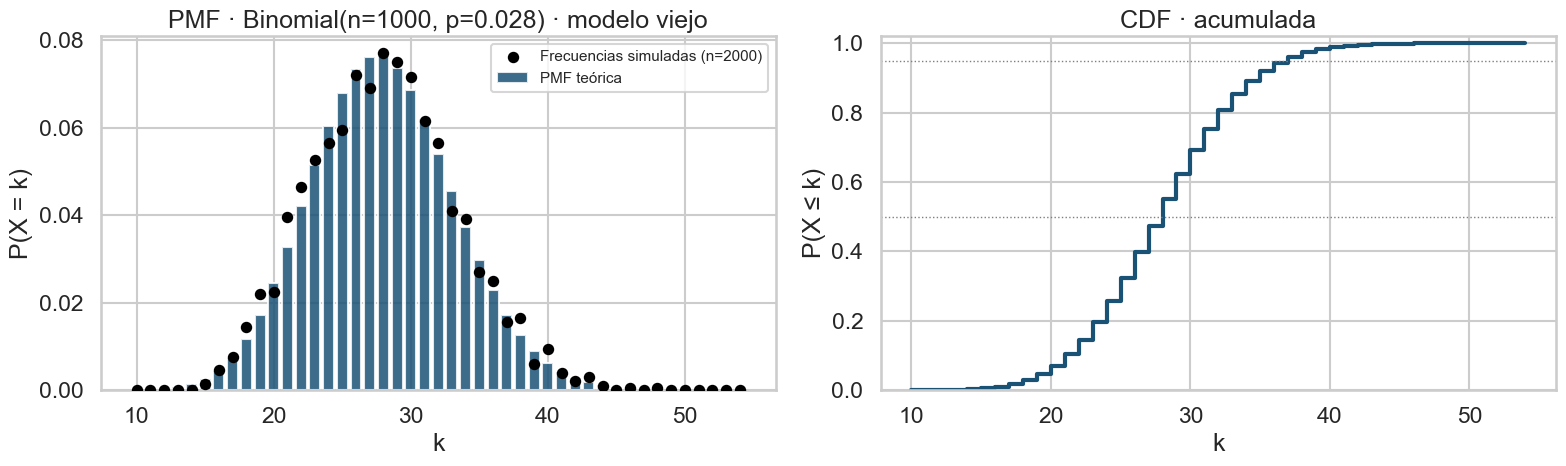

In [15]:
# Plot
graficar_discreta(bino_viejo, np.arange(10, 55),
                  "Binomial(n=1000, p=0.028) · modelo viejo",
                  PAL["binomial"])


**Lectura.** Las barras azules son la PMF teórica. Los puntos negros
son la frecuencia observada en 2.000 semanas simuladas. Coinciden bien,
confirmando que `rvs` muestrea de la distribución correcta. La CDF de la
derecha muestra que con el modelo viejo el 95% de las semanas vas a ver
menos de 36 aprobados; observar 50 sería ruido extremo y probable señal
del nuevo modelo.


## 4. Poisson · dimensionamiento del equipo antifraude

**Caso BancoSur.** Llegan en promedio 4.2 alertas de fraude por día.
Cada analista puede investigar 1 alerta por turno. Marta tiene que decidir
cuántos analistas contratar para cumplir un SLA del 95% de cobertura.

Dimensionar al promedio (4 o 5 analistas) falla la mitad de los días.
Necesita el cuantil 95% de la distribución del número de alertas.


In [16]:
lam = 4.2
poi = stats.poisson(mu=lam)
print("Antifraude: Poisson(λ = 4.2 alertas/día)")


Antifraude: Poisson(λ = 4.2 alertas/día)


In [17]:
# E[X] = Var[X] = λ  · propiedad clásica de Poisson
resumen(poi, "Poisson(λ=4.2)")


--- Poisson(λ=4.2) ---
E[X]   = 4.2000
Var[X] = 4.2000
SD[X]  = 2.0494
P05    = 1.0000
P50    = 4.0000
P95    = 8.0000


In [18]:
# pmf · probabilidad de cada cantidad de alertas
ks = np.arange(0, 15)
for k in [0, 2, 4, 6, 8, 10]:
    print(f"P(X = {k:2d}) = {poi.pmf(k):.4f}")


P(X =  0) = 0.0150
P(X =  2) = 0.1323
P(X =  4) = 0.1944
P(X =  6) = 0.1143
P(X =  8) = 0.0360
P(X = 10) = 0.0071


In [19]:
# cdf · cobertura SLA según capacidad
for capacidad in range(4, 12):
    cobertura = poi.cdf(capacidad)
    saturacion = 1 - cobertura
    print(f"Capacidad = {capacidad} analistas · cobertura = {cobertura:.3%} · saturación = {saturacion:.3%}")


Capacidad = 4 analistas · cobertura = 58.983% · saturación = 41.017%
Capacidad = 5 analistas · cobertura = 75.314% · saturación = 24.686%
Capacidad = 6 analistas · cobertura = 86.746% · saturación = 13.254%
Capacidad = 7 analistas · cobertura = 93.606% · saturación = 6.394%
Capacidad = 8 analistas · cobertura = 97.207% · saturación = 2.793%
Capacidad = 9 analistas · cobertura = 98.887% · saturación = 1.113%
Capacidad = 10 analistas · cobertura = 99.593% · saturación = 0.407%
Capacidad = 11 analistas · cobertura = 99.863% · saturación = 0.137%


In [20]:
# ppf · capacidad mínima para cumplir SLA 95% y 99%
sla_95 = int(poi.ppf(0.95))
sla_99 = int(poi.ppf(0.99))
print(f"Capacidad mínima SLA 95%: {sla_95} analistas")
print(f"Capacidad mínima SLA 99%: {sla_99} analistas")
print(f"Regla rápida λ + 2√λ      = {lam + 2*np.sqrt(lam):.1f}")


Capacidad mínima SLA 95%: 8 analistas
Capacidad mínima SLA 99%: 10 analistas
Regla rápida λ + 2√λ      = 8.3


In [21]:
# rvs · simular un año (365 días) y ver cuántos días saturaron a 7
dias_simulados = poi.rvs(size=365)
saturados_7 = (dias_simulados > 7).sum()
saturados_5 = (dias_simulados > 5).sum()
print(f"Año simulado de 365 días:")
print(f"  Días con > 5 alertas: {saturados_5}  ({saturados_5/365:.1%})")
print(f"  Días con > 7 alertas: {saturados_7}  ({saturados_7/365:.1%})")


Año simulado de 365 días:
  Días con > 5 alertas: 92  (25.2%)
  Días con > 7 alertas: 24  (6.6%)


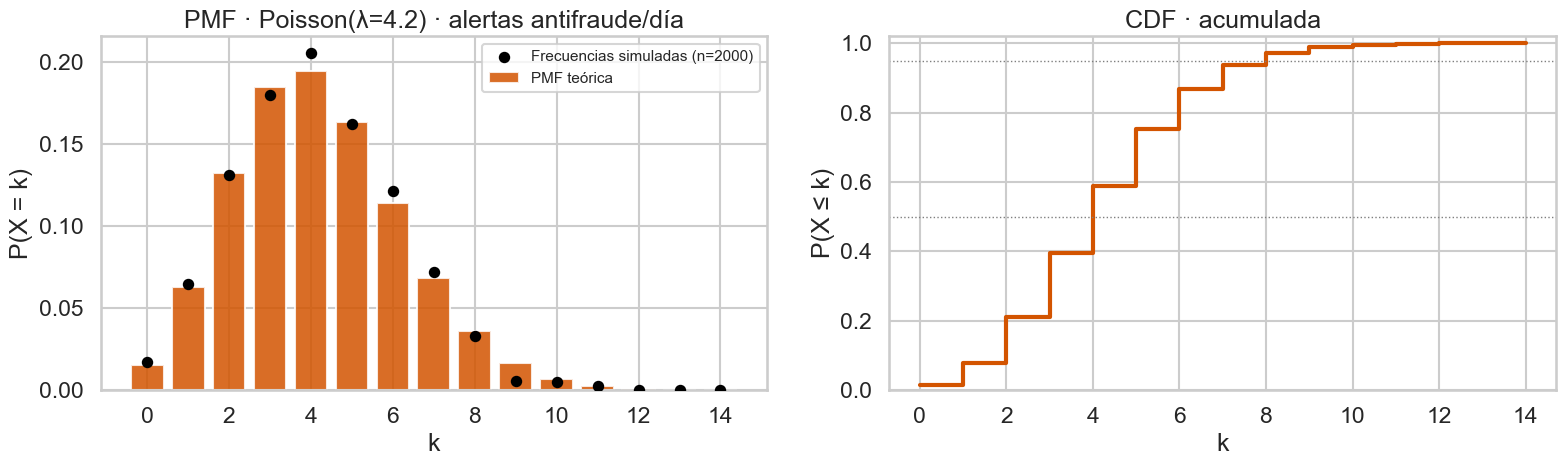

In [22]:
# Plot
graficar_discreta(poi, ks, "Poisson(λ=4.2) · alertas antifraude/día",
                  PAL["poisson"], n_sim=2000)


**Lectura.** La línea punteada del 95% en la CDF te muestra dónde poner
la capacidad. Para Poisson(4.2) corta en X = 8: contratar 8 analistas cubre
el 95% de los días. Cualquier número menor implica saturación con la
probabilidad complementaria. Este mismo razonamiento aplica a call centers,
servidores, técnicos, y stock de seguridad.


## 5. Log-normal · ticket de préstamos personales

**Caso BancoSur.** Los montos solicitados en préstamos personales se
distribuyen log-normal. Esto es típico de variables económicas: muchos
préstamos chicos, pocos préstamos enormes, asimetría positiva. La media
está **siempre** por encima de la mediana, y reportar "ticket promedio"
sobreestima al cliente típico.

**Parametrización scipy.** `stats.lognorm(s=σ, scale=exp(μ))` donde
X = exp(μ + σ·Z) con Z normal estándar. Para μ_log = 9, σ_log = 0.9:
mediana ≈ exp(9) = 8.103, media = exp(9 + 0.405) ≈ 12.124.


In [23]:
mu_log, sig_log = 9.0, 0.9
ln = stats.lognorm(s=sig_log, scale=np.exp(mu_log))
print(f"Log-normal con μ_log = {mu_log}, σ_log = {sig_log}")


Log-normal con μ_log = 9.0, σ_log = 0.9


In [24]:
# Esperanza y mediana · NO coinciden en distribuciones asimétricas
print(f"E[X]     = {ln.mean():.2f}      ticket promedio reportado")
print(f"Mediana  = {ln.median():.2f}     cliente del medio (P50)")
print(f"Moda     = {np.exp(mu_log - sig_log**2):.2f}      monto más frecuente")
print(f"SD[X]    = {ln.std():.2f}")
print(f"Brecha media/mediana: {(ln.mean()/ln.median() - 1)*100:.1f}%")


E[X]     = 12148.97      ticket promedio reportado
Mediana  = 8103.08     cliente del medio (P50)
Moda     = 3604.72      monto más frecuente
SD[X]    = 13571.59
Brecha media/mediana: 49.9%


In [25]:
# pdf · densidad en valores clave
for x in [3000, 8000, 12000, 30000, 80000]:
    print(f"f({x:>6,}) = {ln.pdf(x):.6f}")


f( 3,000) = 0.000080
f( 8,000) = 0.000055
f(12,000) = 0.000034
f(30,000) = 0.000005
f(80,000) = 0.000000


In [26]:
# cdf · porcentaje de préstamos hasta cierto monto
for x in [5000, 10000, 20000, 50000]:
    print(f"P(X ≤ {x:>6,}) = {ln.cdf(x):.3%}")


P(X ≤  5,000) = 29.582%
P(X ≤ 10,000) = 59.240%
P(X ≤ 20,000) = 84.228%
P(X ≤ 50,000) = 97.841%


In [27]:
# ppf · cuantiles para reportar al directorio
for q in [0.10, 0.25, 0.50, 0.75, 0.90, 0.99]:
    print(f"P{int(q*100):02d} = {ln.ppf(q):>10,.0f}")


P10 =      2,557
P25 =      4,416
P50 =      8,103
P75 =     14,869
P90 =     25,678
P99 =     65,756


In [28]:
# rvs · simular 1.000 préstamos
muestra = ln.rvs(size=1000)
print(f"Media muestral    = {muestra.mean():.2f}")
print(f"Mediana muestral  = {np.median(muestra):.2f}")
print(f"Máximo            = {muestra.max():.2f}")
print(f"Top 5% concentra  = {muestra[muestra >= np.percentile(muestra, 95)].sum() / muestra.sum():.1%} del volumen")


Media muestral    = 12314.86
Mediana muestral  = 8124.08
Máximo            = 169395.49
Top 5% concentra  = 23.4% del volumen


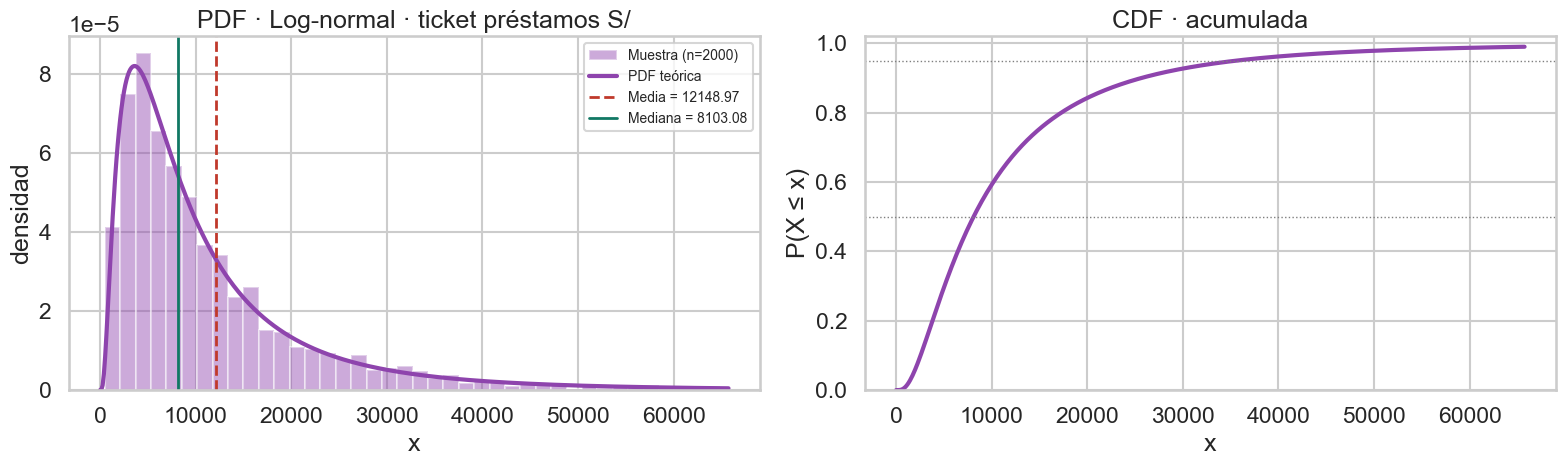

In [29]:
# Plot · cortamos cola visual en P99 para que se vea el cuerpo
xs = np.linspace(0, ln.ppf(0.99), 500)
graficar_continua(ln, xs, "Log-normal · ticket préstamos S/",
                  PAL["lognormal"], n_sim=2000, hist_max=ln.ppf(0.99))


**Lectura.** La media (línea roja) cae a la derecha de la mediana
(línea verde). En log-normal eso ocurre **siempre**: la cola larga
empuja la media hacia arriba. Si tu KPI dice "ticket promedio" pero
los datos son log-normales, estás sobreestimando al cliente típico.
La regla operativa: reportar mediana, o reportar ambas y explicitar
la asimetría.


## 6. Exponencial · tiempo hasta default

**Caso BancoSur.** Para provisionar bien, Marta necesita modelar a qué
velocidad se "queman" los créditos. La exponencial modela el tiempo
hasta el primer evento (default, churn, falla) cuando la tasa de hazard
es constante. Propiedad clave: **no tiene memoria**. Lo que ya sobrevivió
no cuenta.

**Parametrización scipy.** `stats.expon(scale=1/λ)`. Si λ = 0.071/mes,
entonces `scale = 14.08 meses` (la vida media).


In [30]:
lam = 0.071  # tasa de default mensual
expo = stats.expon(scale=1/lam)
print(f"Exponencial(λ = {lam}/mes)  ↔  vida media = {1/lam:.2f} meses")


Exponencial(λ = 0.071/mes)  ↔  vida media = 14.08 meses


In [31]:
resumen(expo, f"Exp(λ={lam})", cuantiles=(0.1, 0.25, 0.5, 0.9))
print(f"Mediana cerrada: ln(2)/λ = {np.log(2)/lam:.2f} meses")


--- Exp(λ=0.071) ---
E[X]   = 14.0845
Var[X] = 198.3733
SD[X]  = 14.0845
P10    = 1.4840
P25    = 4.0519
P50    = 9.7626
P90    = 32.4308
Mediana cerrada: ln(2)/λ = 9.76 meses


In [32]:
# pdf · densidad decreciente
for t in [0, 3, 6, 12, 24, 36]:
    print(f"f({t:2d} meses) = {expo.pdf(t):.4f}")


f( 0 meses) = 0.0710
f( 3 meses) = 0.0574
f( 6 meses) = 0.0464
f(12 meses) = 0.0303
f(24 meses) = 0.0129
f(36 meses) = 0.0055


In [33]:
# cdf · probabilidad de defaultear ANTES del horizonte
for t in [3, 6, 12, 18, 24, 36, 48]:
    print(f"P(T ≤ {t:>2d} meses) = {expo.cdf(t):.3%}")


P(T ≤  3 meses) = 19.184%
P(T ≤  6 meses) = 34.688%
P(T ≤ 12 meses) = 57.344%
P(T ≤ 18 meses) = 72.141%
P(T ≤ 24 meses) = 81.805%
P(T ≤ 36 meses) = 92.239%
P(T ≤ 48 meses) = 96.689%


In [34]:
# ppf · ¿en qué mes el 25%, 50%, 90% ya defaulteó?
for q in [0.10, 0.25, 0.50, 0.75, 0.90]:
    print(f"P{int(q*100):02d}: a los {expo.ppf(q):.1f} meses ya defaulteó el {int(q*100)}% de la cartera")


P10: a los 1.5 meses ya defaulteó el 10% de la cartera
P25: a los 4.1 meses ya defaulteó el 25% de la cartera
P50: a los 9.8 meses ya defaulteó el 50% de la cartera
P75: a los 19.5 meses ya defaulteó el 75% de la cartera
P90: a los 32.4 meses ya defaulteó el 90% de la cartera


In [35]:
# Propiedad "sin memoria": P(T > 12+6 | T > 12) = P(T > 6)
P_supera_6  = 1 - expo.cdf(6)
P_supera_18_dado_supera_12 = (1 - expo.cdf(18)) / (1 - expo.cdf(12))
print(f"P(T > 6)                = {P_supera_6:.4f}")
print(f"P(T > 18 | T > 12)      = {P_supera_18_dado_supera_12:.4f}")
print("Iguales: la exponencial NO tiene memoria.")


P(T > 6)                = 0.6531
P(T > 18 | T > 12)      = 0.6531
Iguales: la exponencial NO tiene memoria.


In [36]:
# rvs · simular 2.000 créditos
tiempos = expo.rvs(size=2000)
print(f"Mediana muestral     = {np.median(tiempos):.2f} meses")
print(f"% default antes 12 m = {(tiempos <= 12).mean():.2%}")
print(f"% default antes 24 m = {(tiempos <= 24).mean():.2%}")


Mediana muestral     = 10.09 meses
% default antes 12 m = 55.40%
% default antes 24 m = 80.90%


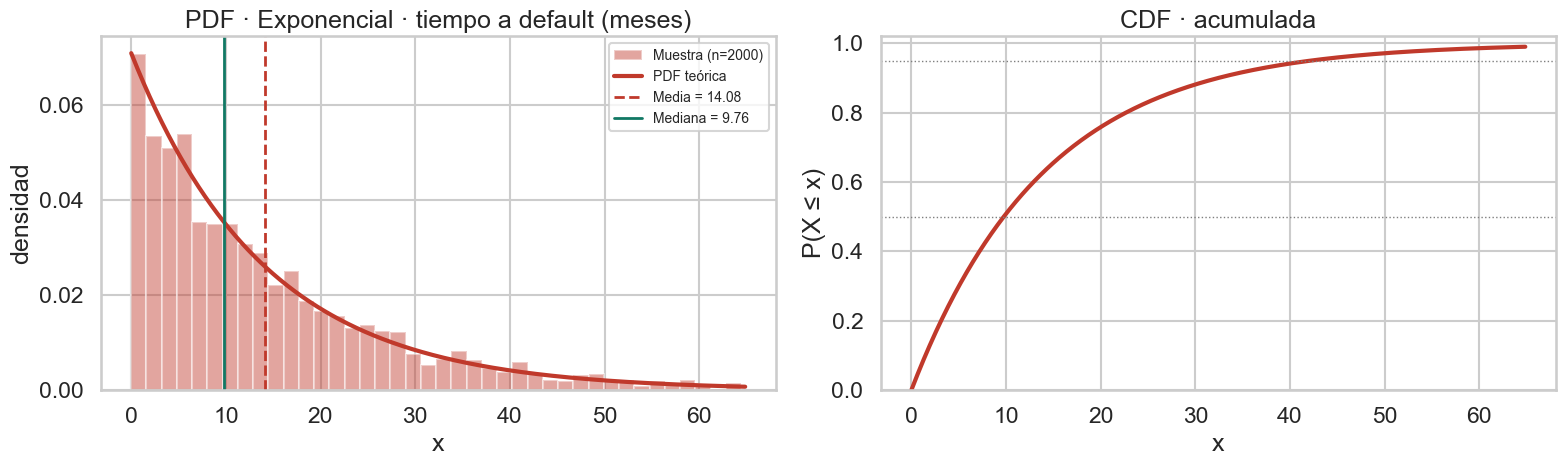

In [37]:
# Plot
xs = np.linspace(0, expo.ppf(0.99), 500)
graficar_continua(expo, xs, "Exponencial · tiempo a default (meses)",
                  PAL["exponencial"], n_sim=2000, hist_max=expo.ppf(0.99))


**Lectura.** La densidad cae monotónicamente desde t=0. La mayor parte
de la masa está en los primeros meses, lo que tiene sentido: si la tasa de
hazard es constante, lo más probable es defaultear pronto. La propiedad
"sin memoria" se verificó arriba numéricamente: condicionar en sobrevivir
12 meses no cambia la distribución del tiempo restante.


## 7. Normal · payout regulatorio de máquinas tragamonedas

**Caso BancoSur Gaming.** La división de gaming opera 12.000 máquinas.
El payout regulatorio es 92% con tolerancia de control de calidad σ = 0.5pp.
Cualquier máquina que salga de **μ ± 3σ** activa alerta de auditoría
(regla industrial estándar).


In [38]:
mu, sigma = 0.92, 0.005   # 92% con 0.5 punto porcentual de SD
nor = stats.norm(loc=mu, scale=sigma)
print(f"Normal(μ = {mu*100:.1f}%, σ = {sigma*100:.2f}pp)")


Normal(μ = 92.0%, σ = 0.50pp)


In [39]:
resumen(nor, "N(0.92, 0.005²)")


--- N(0.92, 0.005²) ---
E[X]   = 0.9200
Var[X] = 0.0000
SD[X]  = 0.0050
P05    = 0.9118
P50    = 0.9200
P95    = 0.9282


In [40]:
# pdf · densidad en valores clave
for x in [0.905, 0.915, 0.920, 0.925, 0.935]:
    print(f"f({x:.3f}) = {nor.pdf(x):.2f}")


f(0.905) = 0.89
f(0.915) = 48.39
f(0.920) = 79.79
f(0.925) = 48.39
f(0.935) = 0.89


In [41]:
# cdf · ¿qué % de máquinas están por debajo/encima de un umbral?
print(f"P(X ≤ 0.910) = {nor.cdf(0.910):.4%}   máquinas que pagan poco (oportunidad de auditoría)")
print(f"P(X ≥ 0.930) = {1 - nor.cdf(0.930):.4%}   máquinas que pagan demasiado (descalibradas)")


P(X ≤ 0.910) = 2.2750%   máquinas que pagan poco (oportunidad de auditoría)
P(X ≥ 0.930) = 2.2750%   máquinas que pagan demasiado (descalibradas)


In [42]:
# ppf · límites del intervalo del 95% central
lim_inf = nor.ppf(0.025)
lim_sup = nor.ppf(0.975)
print(f"95% central: [{lim_inf:.4f}, {lim_sup:.4f}]  ↔  [{lim_inf*100:.2f}%, {lim_sup*100:.2f}%]")

# Banda de auditoría μ ± 3σ
print(f"Banda μ ± 3σ: [{mu - 3*sigma:.4f}, {mu + 3*sigma:.4f}]")
print(f"P(fuera de μ ± 3σ) = {2 * nor.cdf(mu - 3*sigma):.4%}")


95% central: [0.9102, 0.9298]  ↔  [91.02%, 92.98%]
Banda μ ± 3σ: [0.9050, 0.9350]
P(fuera de μ ± 3σ) = 0.2700%


In [43]:
# rvs · simular las 12.000 máquinas de la red
payouts = nor.rvs(size=12000)
fuera_3sigma = ((payouts < mu - 3*sigma) | (payouts > mu + 3*sigma)).sum()
print(f"Máquinas fuera de ±3σ: {fuera_3sigma} de 12.000 ({fuera_3sigma/12000:.2%})")
print(f"Esperadas teóricamente: {12000 * 2 * nor.cdf(mu - 3*sigma):.0f}")


Máquinas fuera de ±3σ: 27 de 12.000 (0.22%)
Esperadas teóricamente: 32


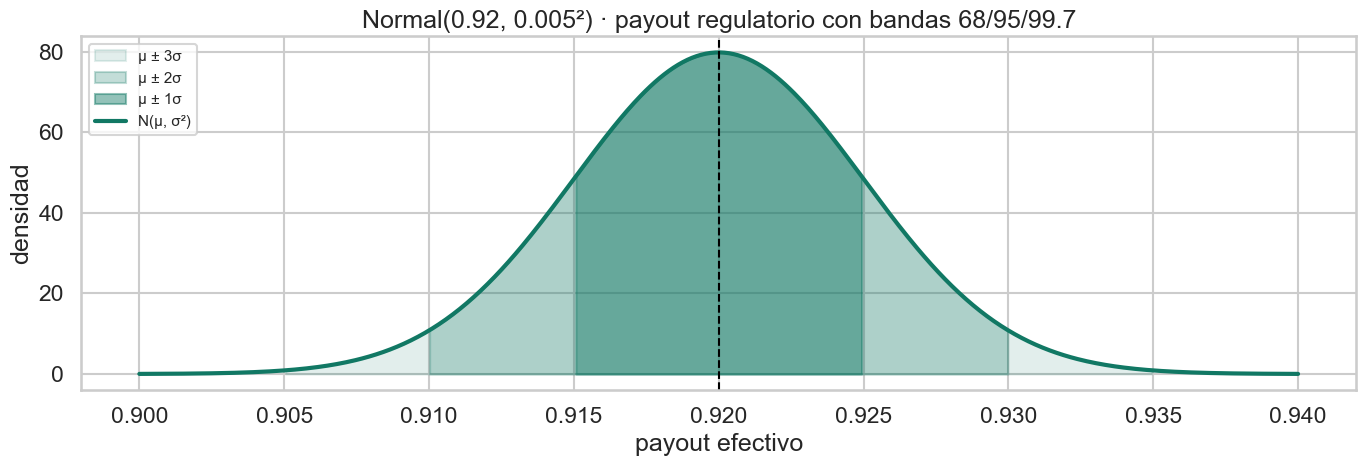

In [44]:
# Plot con bandas 68-95-99.7
xs = np.linspace(mu - 4*sigma, mu + 4*sigma, 500)
fig, ax = plt.subplots(figsize=(14, 5))

# Bandas concéntricas
for k, alpha in [(3, 0.12), (2, 0.25), (1, 0.45)]:
    mask = (xs >= mu - k*sigma) & (xs <= mu + k*sigma)
    ax.fill_between(xs[mask], 0, nor.pdf(xs[mask]),
                    color=PAL["normal"], alpha=alpha,
                    label=f"μ ± {k}σ")

ax.plot(xs, nor.pdf(xs), color=PAL["normal"], lw=3, label="N(μ, σ²)")
ax.axvline(mu, color="black", ls="--", lw=1.5)
ax.set_xlabel("payout efectivo")
ax.set_ylabel("densidad")
ax.set_title("Normal(0.92, 0.005²) · payout regulatorio con bandas 68/95/99.7")
ax.legend(loc="upper left", fontsize=11)
plt.tight_layout()
plt.show()


**Lectura.** La regla 68-95-99.7 de la Normal te da una grilla mental
calibrada. Si las 12.000 máquinas se distribuyen Normal, esperás unas 36
máquinas fuera de ±3σ por **puro azar**. Si auditás y encontrás 200, el
proceso ya no es Normal con esos parámetros: algo cambió. Esta es la lógica
detrás de Six Sigma y control estadístico de procesos en general.


## 8. Teorema del Límite Central · cierre de la sesión

**Caso BancoSur.** ¿Por qué los promedios mensuales del dashboard de Marta
son tan estables, aun cuando los datos crudos diarios son asimétricos y
ruidosos? El TLC: el promedio de n variables independientes converge a
una **Normal**, sin importar la distribución original, siempre que n sea
suficiente.

**Implicancia.** Podés hacer inferencia (intervalos de confianza, pruebas
de hipótesis, A/B testing) sin conocer la distribución real de los datos.
Por eso el TLC es la base de toda la estadística inferencial.


In [45]:
# Tomamos como caso la log-normal de tickets de préstamos (sección 5)
mu_log, sig_log = 9.0, 0.9
ln_tlc = stats.lognorm(s=sig_log, scale=np.exp(mu_log))

mu_pob  = ln_tlc.mean()
sd_pob  = ln_tlc.std()
print(f"Población log-normal:  μ = {mu_pob:.2f}  σ = {sd_pob:.2f}")


Población log-normal:  μ = 12148.97  σ = 13571.59


In [46]:
# Tomamos M = 2.000 muestras de tamaño n = 30, calculamos la media de cada una
np.random.seed(42)
M, n = 2000, 30
medias = np.array([ln_tlc.rvs(size=n).mean() for _ in range(M)])

se_teorica   = sd_pob / np.sqrt(n)
se_empirica  = medias.std(ddof=1)

print(f"Media de las medias    = {medias.mean():.2f}   (debe ≈ {mu_pob:.2f})")
print(f"SE teórica (σ/√n)      = {se_teorica:.2f}")
print(f"SE empírica            = {se_empirica:.2f}")


Media de las medias    = 12142.78   (debe ≈ 12148.97)
SE teórica (σ/√n)      = 2477.82
SE empírica            = 2461.81


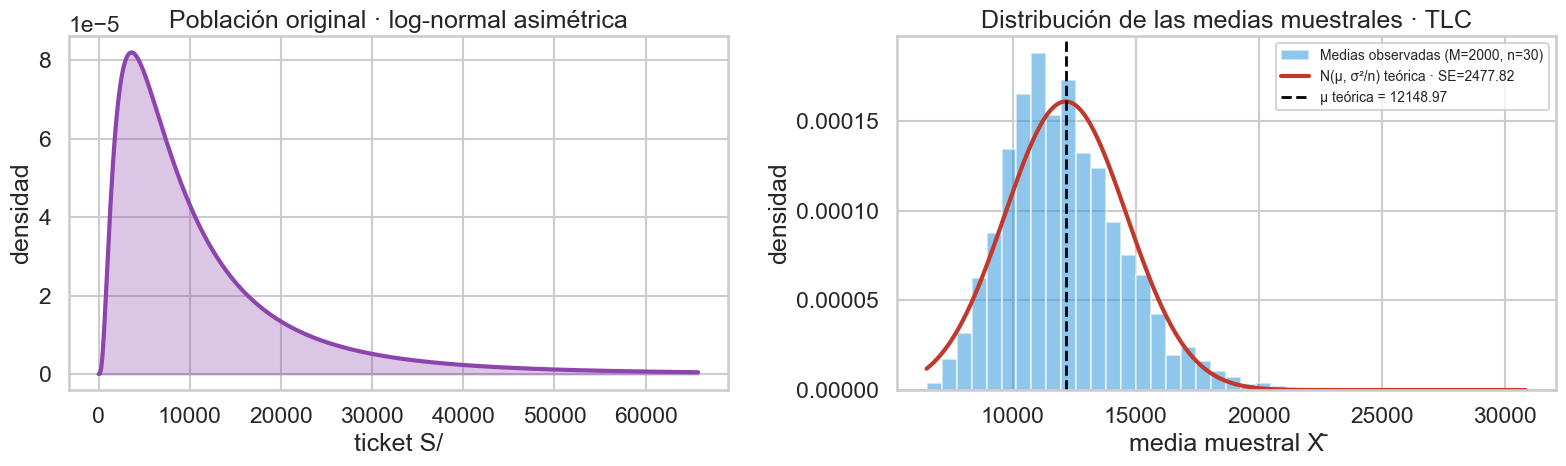

In [47]:
# Visualización: histograma de medias + Normal teórica superpuesta
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel 1: la población log-normal cruda
xs_pob = np.linspace(0, ln_tlc.ppf(0.99), 500)
axes[0].plot(xs_pob, ln_tlc.pdf(xs_pob), color=PAL["lognormal"], lw=3)
axes[0].fill_between(xs_pob, 0, ln_tlc.pdf(xs_pob), color=PAL["lognormal"], alpha=0.30)
axes[0].set_title("Población original · log-normal asimétrica")
axes[0].set_xlabel("ticket S/")
axes[0].set_ylabel("densidad")

# Panel 2: distribución de las medias muestrales + Normal teórica
axes[1].hist(medias, bins=40, density=True, alpha=0.55, color=PAL["tlc"],
             edgecolor="white", label=f"Medias observadas (M={M}, n={n})")
xs_med = np.linspace(medias.min(), medias.max(), 300)
normal_teo = stats.norm(loc=mu_pob, scale=se_teorica)
axes[1].plot(xs_med, normal_teo.pdf(xs_med), color="#c0392b", lw=3,
             label=f"N(μ, σ²/n) teórica · SE={se_teorica:.2f}")
axes[1].axvline(mu_pob, color="black", ls="--", lw=2, label=f"μ teórica = {mu_pob:.2f}")
axes[1].set_title("Distribución de las medias muestrales · TLC")
axes[1].set_xlabel("media muestral X̄")
axes[1].set_ylabel("densidad")
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()


In [48]:
# Verificamos cómo cambia la SE con n  (regla σ/√n)
for n in [5, 10, 30, 100, 500]:
    medias_n = np.array([ln_tlc.rvs(size=n).mean() for _ in range(500)])
    se_teo = sd_pob / np.sqrt(n)
    se_emp = medias_n.std(ddof=1)
    print(f"n = {n:3d}  ·  SE teórica = {se_teo:6.2f}  ·  SE empírica = {se_emp:6.2f}")


n =   5  ·  SE teórica = 6069.40  ·  SE empírica = 6479.87
n =  10  ·  SE teórica = 4291.72  ·  SE empírica = 4267.48
n =  30  ·  SE teórica = 2477.82  ·  SE empírica = 2428.66
n = 100  ·  SE teórica = 1357.16  ·  SE empírica = 1348.09
n = 500  ·  SE teórica = 606.94  ·  SE empírica = 613.48


**Lectura del TLC.**

1. **El histograma azul es una campana**, aun cuando la población original
   (panel izquierdo) es claramente asimétrica. La asimetría se "promedia"
   y desaparece.
2. **La SE empírica coincide con σ/√n.** Esta es la fórmula más usada en
   estadística aplicada: cuando duplicás n, la SE no se reduce a la mitad
   sino en √2. Para reducir la SE a la mitad necesitás **4×** el tamaño
   de muestra.
3. **Implicancia operativa.** Cuando reportás un KPI mensual basado en
   miles de transacciones diarias, ese promedio es estable aun si los
   datos crudos son log-normales o exponenciales. Por eso los promedios
   funcionan tan bien para decisiones de gestión.

---

## Cierre

Lo que cubrimos en esta notebook se generaliza a cualquier distribución
de `scipy.stats`. La API es uniforme:

```python
dist = stats.<nombre>(parametros)
dist.rvs(size=n)     # simular
dist.pdf(x)          # densidad (continua)
dist.pmf(k)          # probabilidad puntual (discreta)
dist.cdf(x)          # acumulada
dist.ppf(q)          # inversa de la acumulada (cuantil)
dist.mean()          # esperanza teórica
dist.var()           # varianza teórica
dist.std()           # desviación teórica
```

Aprender este patrón con las 6 distribuciones del caso BancoSur te
habilita a usar las 100+ distribuciones de scipy con el mismo flujo.

La próxima sesión arranca con inferencia: vamos a usar el TLC para
construir intervalos de confianza y pruebas de hipótesis sobre KPIs reales.
